## Import Data from Socograta.Gov

In [1]:
import pandas as pd
from sodapy import Socrata

# Unauthenticated client only works with public data sets. Note 'None'
# in place of application token, and no username or password:
#client = Socrata("data.transportation.gov", None)

client = Socrata( "data.transportation.gov",
                     '1hCte9vYL7IpE7pFTGR1cbn8y',
                     username="hugo.baca4515@coyote.csusb.edu",
                     password="Hugobacaalex1!" )

# First 2000 results, returned as JSON from API / converted to Python list of
# dictionaries by sodapy.
results = client.get_all("7wn6-i5b9", year='2023')

# Convert to pandas DataFrame
Raw_2023 = pd.DataFrame.from_records(results)

#let's see what we get back
print(Raw_2023)


     railroadcode                        railroadname  year incidentnumber  \
0             ARR         Alaska Railroad Corporation  2023        2023086   
1             ARR         Alaska Railroad Corporation  2023        2023111   
2            BNSF                BNSF Railway Company  2023      CA0223201   
3             FEC  Florida East Coast Railway Company  2023      X31071323   
4             FEC  Florida East Coast Railway Company  2023      X32072623   
...           ...                                 ...   ...            ...   
1363          CSX                  CSX Transportation  2023      000212582   
1364          CSX                  CSX Transportation  2023      000212837   
1365          CSX                  CSX Transportation  2023      000212120   
1366          CSX                  CSX Transportation  2023      000212966   
1367           UP      Union Pacific Railroad Company  2023      0123RM025   

     incidentyear incidentmonth maintenancerailroadcode  \
0   

### Chekout labels we have to work with 

In [2]:
from numpy.core.fromnumeric import sort

column_headers = list(Raw_2023.columns.values)

column_headers.sort()

print("The Column Headers:")
for header in column_headers:
  print(header)

The Column Headers:
ampm
cityname
countycode
countyname
crossingilluminated
crossingusersinjured
crossinguserskilled
crossingwarning
crossingwarningcode
crossingwarningexpanded1
crossingwarningexpanded2
crossingwarningexpanded3
crossingwarningexpanded4
crossingwarningexpanded5
crossingwarningexpanded6
crossingwarningexpanded7
crossingwarningexpandedcode1
crossingwarningexpandedcode2
crossingwarningexpandedcode3
crossingwarningexpandedcode4
crossingwarningexpandedcode5
crossingwarningexpandedcode6
crossingwarningexpandedcode7
crossingwarningexplanation
crossingwarningexplanationcode
crossingwarninglocation
crossingwarninglocationcode
date
day
district
drivercondition
driverconditioncode
driverinvehicle
driverpassedvehicle
employeesinjured
employeeskilled
equipmentinvolved
equipmentinvolvedcode
equipmentstruck
equipmentstruckcode
equipmenttype
equipmenttypecode
estimatedrecordedspeedcode
estimatedvehiclespeed
form54filed
gradecrossingid
hazmatinvolvement
hazmatinvolvementcode
hazmatrelea

### Set up Labels & Dictionary Search

In [3]:
from numpy import NaN
dictionary_data_raw = pd.read_excel('../Data_Dictionaries/Form_54_Data_Dictionary.xlsx')

dictionary = pd.DataFrame.from_records(dictionary_data_raw)

dictionary.columns.values

dictionary = dictionary.filter(items=['Display Name', 'Description'])

print(dictionary)

                Display Name  \
0    Reporting Railroad Code   
1    Reporting Railroad Name   
2                       Year   
3            Accident Number   
4                   PDF Link   
..                       ...   
168                      NaN   
169                      NaN   
170                      NaN   
171                      NaN   
172                      NaN   

                                           Description  
0    Code of the reporting railroad [Block #1a on F...  
1    Name of the reporting railroad [Block #1 on Fo...  
2                                         Report year   
3    Assigned accident number for the reporting rai...  
4                                     PDF link to form  
..                                                 ...  
168                                                NaN  
169                                                NaN  
170                                                NaN  
171                                          

### Search for Descriptions

name_to_descriptions = ['']

In [4]:
# Create a dictionary to store the corresponding names and descriptions
name_to_description = {}
for index, row in dictionary.iterrows():
    name_to_description[row['Display Name']] = row['Description']

# Get the description for the variable 'report year'
description = name_to_description['Year']
print(description)

#Personal Prefence: Allows me to quickly pull descriptions for variable.

Report year 


Verify data is from only 2023

In [5]:
#i would like to break up data into smaller chunks to make it easier to work with
# such as by 10 years

print(Raw_2023['year'].max())
print(Raw_2023['year'].min())




2023
2023


Peak at data in table form

In [6]:

from tabulate import tabulate
print(tabulate(Raw_2023, headers = 'keys', tablefmt = 'psql'))


+------+----------------+------------------------------------------------------------+--------+------------------+----------------+-----------------+---------------------------+------------------------------------------------------------+--------------------------------+---------------------------+----------------------------+-------------------+-------------------------+---------+-------+--------+----------+--------+----------+----------------------+----------------------+--------------+---------------------+-------------+----------------+----------------------+----------------------+---------------------+-----------------+-------------------+---------------------+-------------------------+------------------------+--------------------+---------------------------+--------------------------------+-------------------------+------------------------+---------------------------+-----------------------+---------------------------------------+-------------------------+---------------------+--

In [7]:
Raw_2023.columns = Raw_2023.columns.str.strip()


In [8]:
columns_to_drop = [
    'railroadcode', 'maintenancerailroadcode', 'maintenancerailroadname',
    'neareststation', 'subdivision', 'reporting_parent_railroad_code',
    'maintenance_parent_railroad_name', 'maintenance_railroad_holding_company',
    'url', 'maintenance_parent_railroad_code', 'maintenance_railroad_smt_grouping',
    'reporting_railroad_holding_company', 'reporting_railroad_smt_grouping',
    'reporting_parent_railroad_name'
]

columns_to_drop = [col for col in columns_to_drop if col in Raw_2023.columns]

Raw_2023.drop(columns=columns_to_drop, inplace=True)


## Data Clean Up

In [9]:
#Explore for NA's, missing data, and redunnacy

isnaValues = Raw_2023.isna()
print(isnaValues)

# Check for NA values
missing_values = Raw_2023.isna().sum()

#check for null values
missing_data = Raw_2023.isnull().sum()
print(missing_data)

# Check for missing data
for column in Raw_2023.columns:
    if missing_values[column] > 0:
        print(f"The column {column} has {missing_values[column]} missing values.")

# Check for redundancy
for column in Raw_2023.columns:
    if Raw_2023[column].duplicated().sum() > 0:
        print(f"The column {column} has {Raw_2023[column].duplicated().sum()} duplicate values.")

#lets try to clean up raw data

# Calculate the percentage of missing values in each column
missing_values = Raw_2023.isna().mean()

# Drop columns with more than 30% missing values
drop_list = [column for column in missing_values.index if missing_values[column] > 0.3]

# Drop the columns
Raw_2023_clean = Raw_2023.drop(columns=drop_list)


# Check the shape of the raw data
print(f"The Raw Data Frame has {Raw_2023.shape[0]} rows and {Raw_2023.shape[1]} columns.")
print(f"The clean data freame has a mean of missing: {missing_values}")
print(f"\n The Raw Data Frame has {len(Raw_2023.columns)} labels.")
print(f"\n The Clean Data Frame now has {len(Raw_2023_clean.columns)} labels.")
print("\n Count of labels dropped: \n", len(Raw_2023.columns) - len(Raw_2023_clean.columns) )
print("\n Deleted Labels: \n", drop_list)
print("\n Cleaned Data Labels: \n", Raw_2023_clean.columns.values)

      railroadname   year  incidentnumber  incidentyear  incidentmonth  \
0            False  False           False         False          False   
1            False  False           False         False          False   
2            False  False           False         False          False   
3            False  False           False         False          False   
4            False  False           False         False          False   
...            ...    ...             ...           ...            ...   
1363         False  False           False         False          False   
1364         False  False           False         False          False   
1365         False  False           False         False          False   
1366         False  False           False         False          False   
1367         False  False           False         False          False   

      maintainenanceincidentnumber  maintenanceincidentyear  \
0                            False              

## Checkout Data after clean up

In [10]:

from tabulate import tabulate
print(tabulate(Raw_2023_clean, headers = 'keys', tablefmt = 'psql'))


+------+------------------------------------------------------------+--------+------------------+----------------+-----------------+--------------------------------+---------------------------+----------------------------+-------------------+-------------------------+---------+-------+--------+----------+--------+----------+--------------+---------------------+-------------+----------------+----------------------+----------------------+---------------------+-----------------+-------------------+---------------------+-------------------------+------------------------+--------------------+---------------------------+--------------------------------+-------------------------+------------------------+---------------------------+-----------------------+---------------------------------------+-------------------------+---------------------+------------------------+--------------------+---------------+------------------+--------------+------------------------+--------------------+------------

### Assess that there is no label with more than 30% na 

In [11]:
missing_values_clean = Raw_2023_clean.isna().mean()


In [12]:
print(missing_values_clean)

railroadname                  0.000000
year                          0.000000
incidentnumber                0.000000
incidentyear                  0.000000
incidentmonth                 0.000000
                                ...   
totalinjuredform55a           0.000000
district                      0.000000
reportkey                     0.000000
reporting_railroad_class      0.146199
maintenance_railroad_class    0.078947
Length: 101, dtype: float64


In [25]:
Engineered_Labels_2023 = pd.DataFrame(Raw_2023_clean['gradecrossingid'])

In [28]:
# Assume fatalities and injuries are columns in the Raw_2023_clean DataFrame
aggregated_data = Raw_2023_clean.groupby('gradecrossingid').agg({
    'totalkilledform57': 'sum',  # Sum of fatalities for each gradecrossingid
    'totalinjuredform57': 'sum',    # Sum of injuries for each gradecrossingid
    'gradecrossingid': 'size'  # Count of occurrences of each gradecrossingid
}).rename(columns={'gradecrossingid': 'id_frequency'}).reset_index()

Engineered_Labels_2023 = Engineered_Labels_2023.merge(aggregated_data, on='gradecrossingid', how='left')


COOK                32
HARRIS              26
LOS ANGELES         23
BROWARD             19
FULTON              19
SHELBY              17
JEFFERSON           16
PALM BEACH          15
MARION              14
MONTGOMERY          13
WAYNE               12
JACKSON             11
MARICOPA            10
MIAMI-DADE          10
ALAMEDA              9
BUTLER               9
POLK                 9
SUFFOLK              9
ALLEN                9
EAST BATON ROUGE     8
Name: countyname, dtype: int64


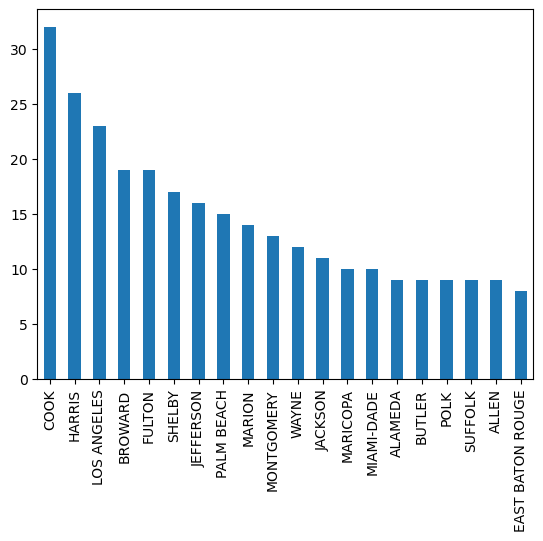

In [29]:
#lets see which county experiences the most accidents
# so basically get a graph x = county, y = number of accidents, all rows in this set are accidents
#get indivial counties and keep track of how many times they appear
import matplotlib.pyplot as plt
import numpy as np
incidentsbycounties = Raw_2023_clean['countyname'].value_counts()
#get the top 10 counties
incidentsbycounties = incidentsbycounties[:20,]

#save to file
np.savez('../2023incidentsbycounties.npz', incidentsbycounties.to_numpy())
print(incidentsbycounties)

#plot the data
incidentsbycounties.plot.bar()
plt.show()


Quantity of unique counties: 570
+-----+---------------------+---------------------+
|     | countyname          |   totalkilledform57 |
|-----+---------------------+---------------------|
|   0 | ADA                 |                   1 |
|   1 | ADAIR               |                   1 |
|   2 | ADAMS               |                   1 |
|   3 | AIKEN               |                   0 |
|   4 | ALAMEDA             |                   1 |
|   5 | ALLEGAN             |                   1 |
|   6 | ALLEGHENY           |                   0 |
|   7 | ALLEN               |                   0 |
|   8 | ARKANSAS            |                   0 |
|   9 | AROOSTOOK           |                   0 |
|  10 | ASCENSION           |                   0 |
|  11 | ASHTABULA           |                   0 |
|  12 | ATASCOSA            |                   0 |
|  13 | AUSTIN              |                   0 |
|  14 | AUTAUGA             |                   0 |
|  15 | BACA                |  

<Figure size 1400x700 with 0 Axes>

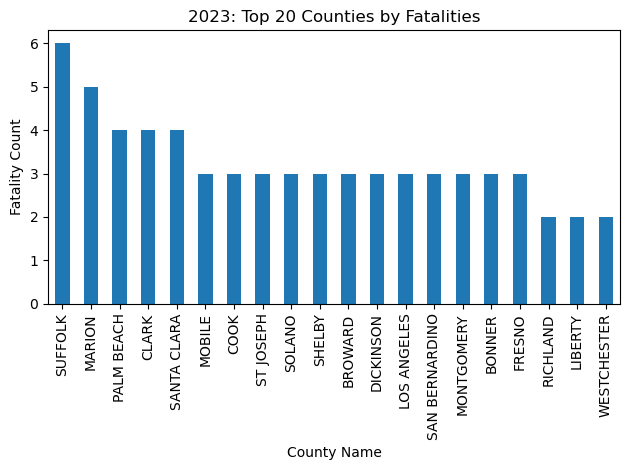

In [30]:
import matplotlib.pyplot as plt
from tabulate import tabulate

# 1. Calculate the number of unique counties
county_count = Raw_2023_clean['countyname'].nunique()
print("Quantity of unique counties:", county_count)
Raw_2023_clean['totalkilledform57'] = pd.to_numeric(Raw_2023_clean['totalkilledform57'], errors='coerce')

# 2. Sum of 'totalkilledform57' grouped by 'countyname'
result_df = Raw_2023_clean.groupby('countyname')['totalkilledform57'].sum().reset_index()
print(tabulate(result_df, headers='keys', tablefmt='psql'))

# 3. Plot top 20 counties by fatalities
top20countiesbyfatalities = result_df.sort_values(by='totalkilledform57', ascending=False).head(20)

plt.figure(figsize=(14, 7))
top20countiesbyfatalities.plot.bar(x='countyname', y='totalkilledform57', legend=False)
plt.title('2023: Top 20 Counties by Fatalities')
plt.xlabel(str('County Name'))
plt.ylabel('Fatality Count')
plt.tight_layout()
plt.show()

#save to file
np.savez('../2023top20countiesbyfatalities.npz', top20countiesbyfatalities.to_numpy())

025422P    4
050330S    3
631785D    3
725759B    3
637728K    3
718062K    3
676300G    3
025430G    3
153762C    2
723692P    2
510017L    2
916933L    2
028442L    2
819330X    2
628146G    2
766163B    2
348506D    2
053938J    2
272640A    2
524223P    2
Name: gradecrossingid, dtype: int64


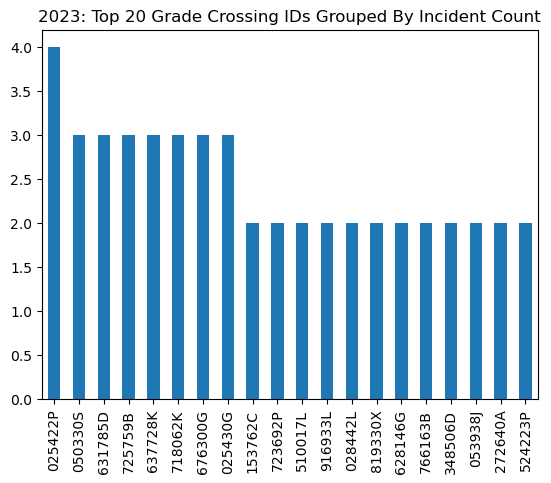

   countyname gradecrossingid  count
0         ADA         819330X      2
1         ADA         819326H      1
2       ADAIR         330391G      1
3       ADAIR         330625H      1
4       ADAMS         070779Y      1
5       ADAMS         072813K      1
6       ADAMS         083178C      1
7       ADAMS         804419H      1
8       ADAMS         804434K      1
9       AIKEN         715767R      1
10    ALAMEDA         749712Y      2
11    ALAMEDA         749634U      1
12    ALAMEDA         749709R      1
13    ALAMEDA         749728V      1
14    ALAMEDA         749774W      1
15    ALAMEDA         751041C      1
16    ALAMEDA         751154H      1
17    ALAMEDA         834232U      1
18    ALLEGAN         234677M      1
19    ALLEGAN         234707C      1


In [32]:
GCF = Raw_2023_clean['gradecrossingid'].value_counts()
print(GCF.head(20))

GCF = GCF[:20,]
GCF.plot.bar(x='index', y='count', title='2023: Top 20 Grade Crossing IDs Grouped By Incident Count')
plt.show()
np.savez('../2023top20GradeCrossingFrequency.npz', GCF.to_numpy())

GCFbycounty = Raw_2023_clean.groupby('countyname')['gradecrossingid'].value_counts().reset_index(name='count')
print(GCFbycounty.head(20))



In [33]:
topcorssingid = Raw_2023_clean[Raw_2023_clean['gradecrossingid'] == '025422P'].get(['countyname', 'statename'])
print(topcorssingid)


    countyname statename
787   MARICOPA   ARIZONA
796   MARICOPA   ARIZONA
798   MARICOPA   ARIZONA
803   MARICOPA   ARIZONA


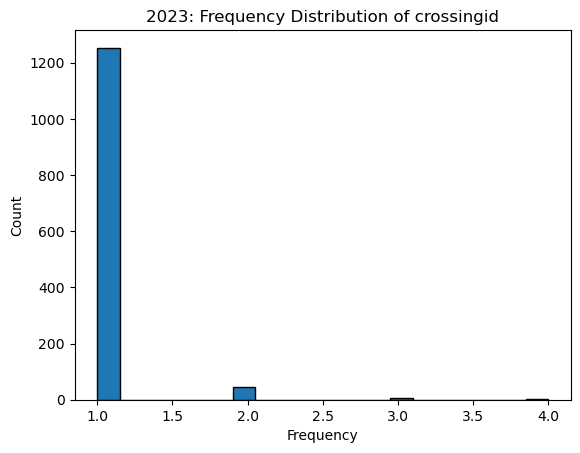

In [34]:
# Assuming you have a DataFrame named df with a 'crossingid' column
# Use value_counts() to get the frequency of each unique crossingid
crossingid_frequency = Raw_2023_clean['gradecrossingid'].value_counts()
#
np.savez('../2023crossingid_frequency.npz', crossingid_frequency.to_numpy() )
# Plot a histogram of the frequencies
plt.hist(crossingid_frequency, bins=20, edgecolor='k')
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.title('2023: Frequency Distribution of crossingid')
plt.show()

/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_1788/1778473320.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(crossingid_frequency, kde=True)


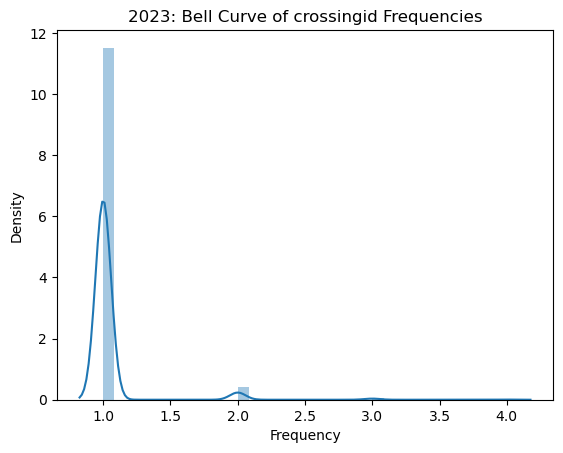

In [35]:
import seaborn as sns

# Assuming you have a DataFrame named df with a 'crossingid' column
# Use value_counts() to get the frequency of each unique crossingid
crossingid_frequency = Raw_2023_clean['gradecrossingid'].value_counts()

# Create a bell curve (normal distribution) plot
sns.distplot(crossingid_frequency, kde=True)
plt.xlabel('Frequency')
plt.ylabel('Density')
plt.title('2023: Bell Curve of crossingid Frequencies')
plt.show()

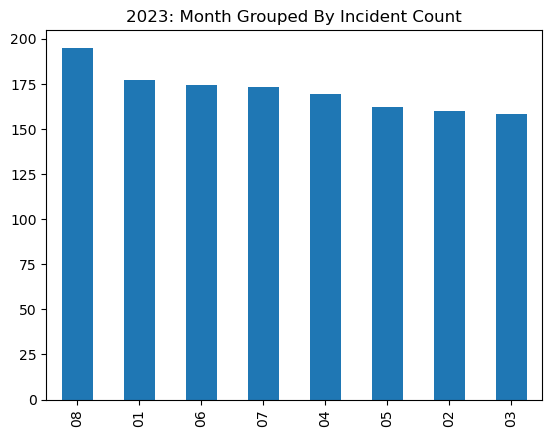

In [40]:
month_frequency = Raw_2023_clean['incidentmonth'].value_counts()

month_frequency.plot.bar(x='index', y='count', title='2023: Month Grouped By Incident Count')
plt.show()

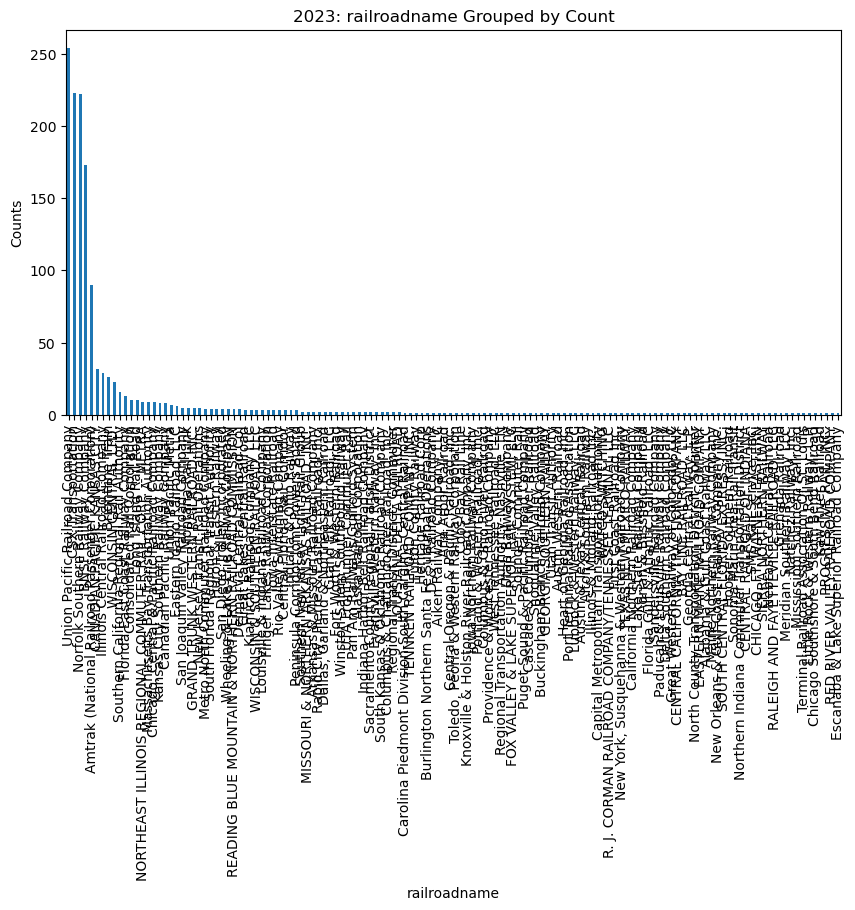

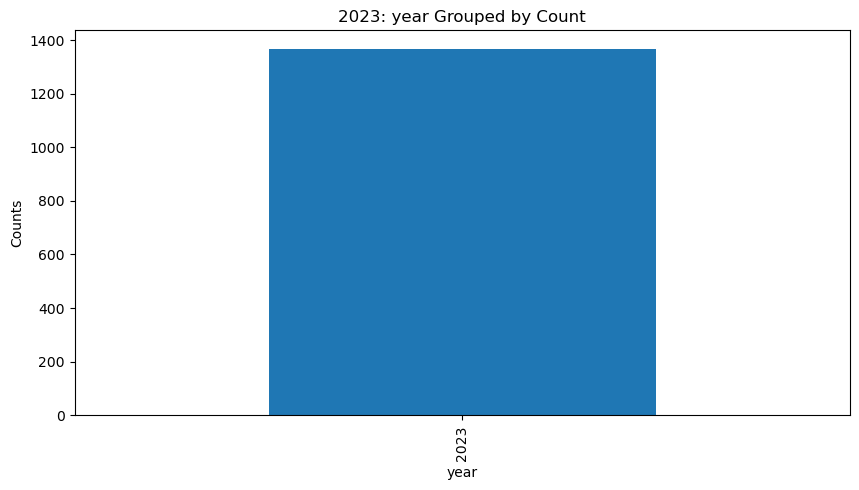

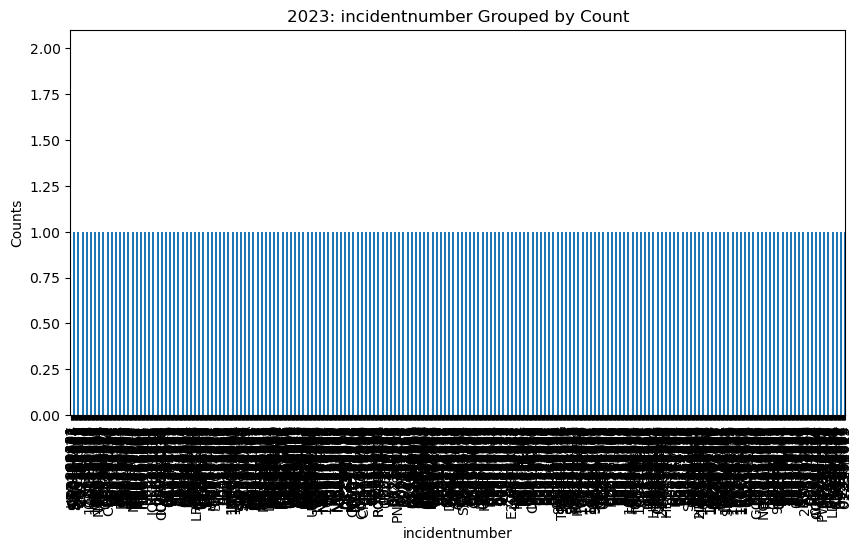

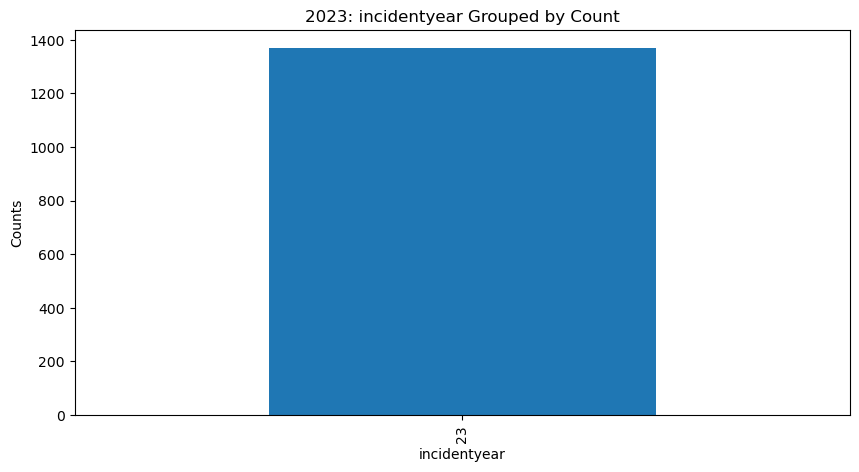

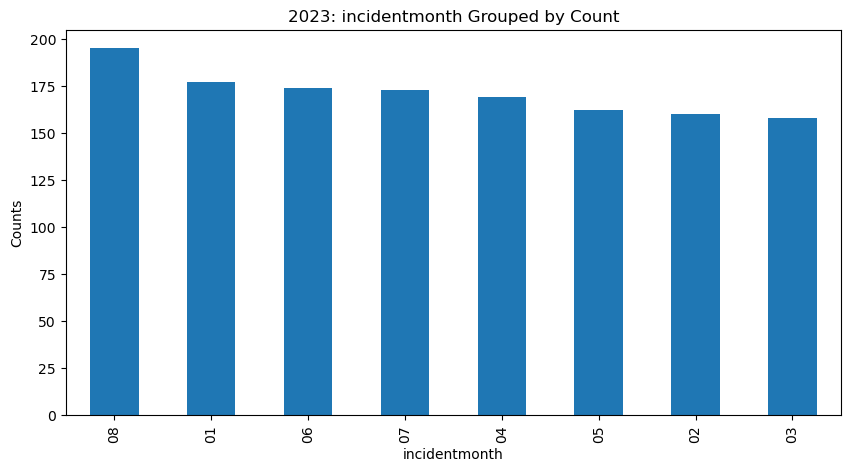

...

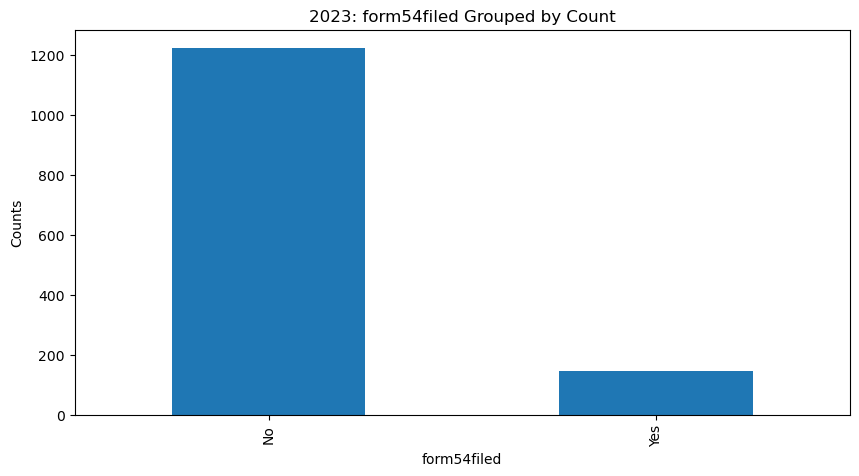

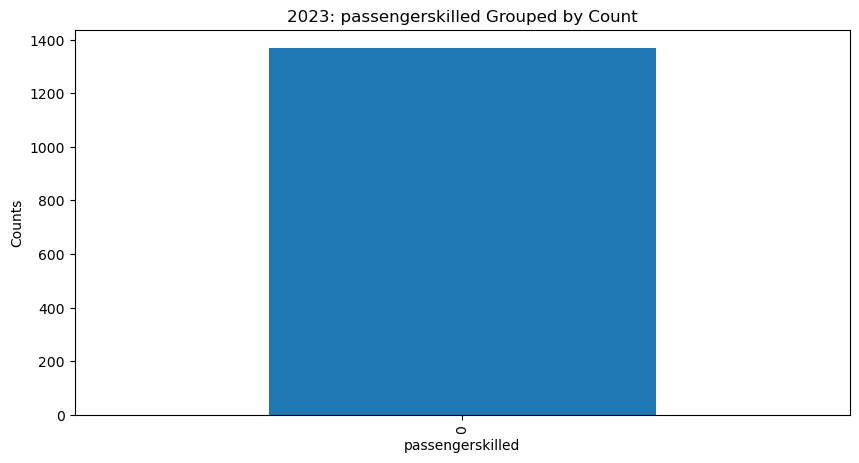

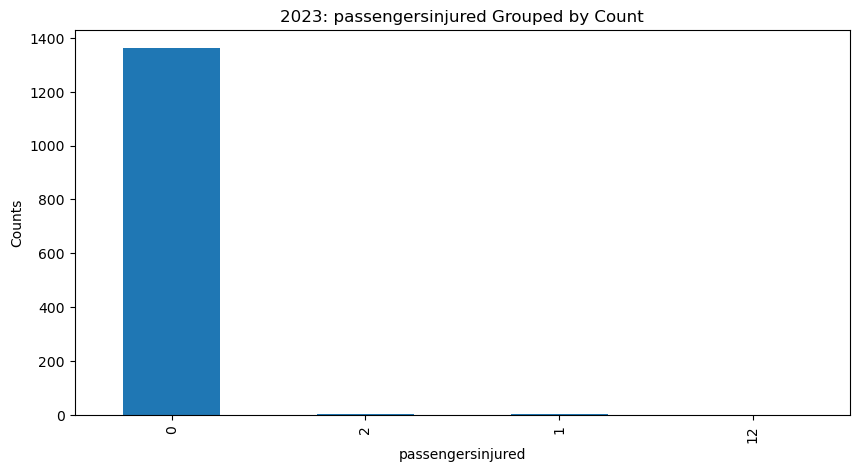

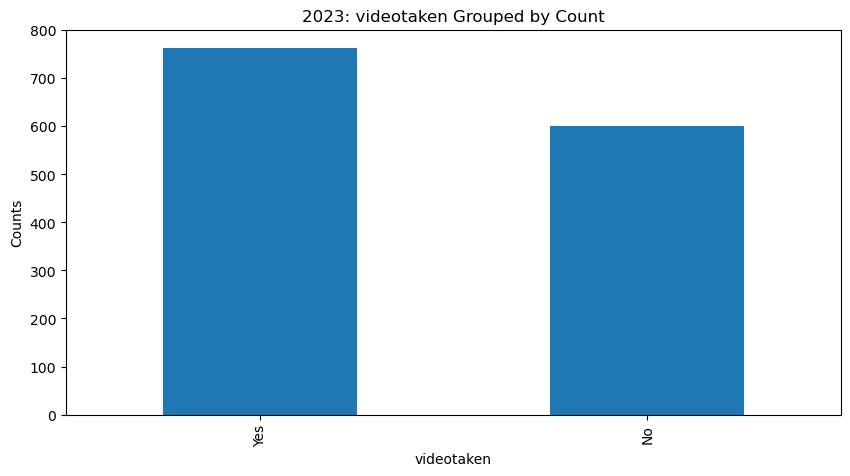

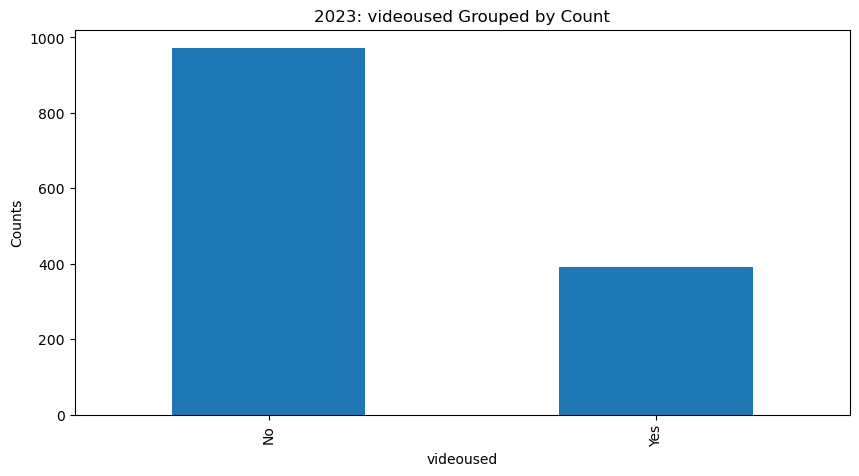

) missing from current font.b/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 13 (
  fig.canvas.print_figure(bytes_io, **kw)


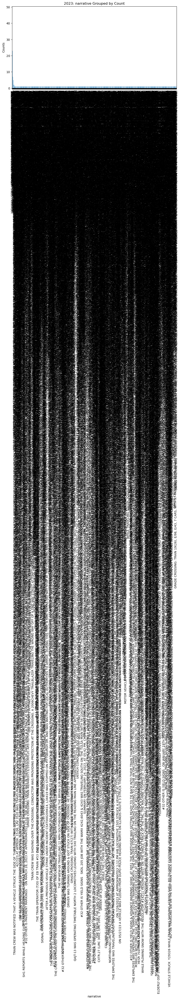

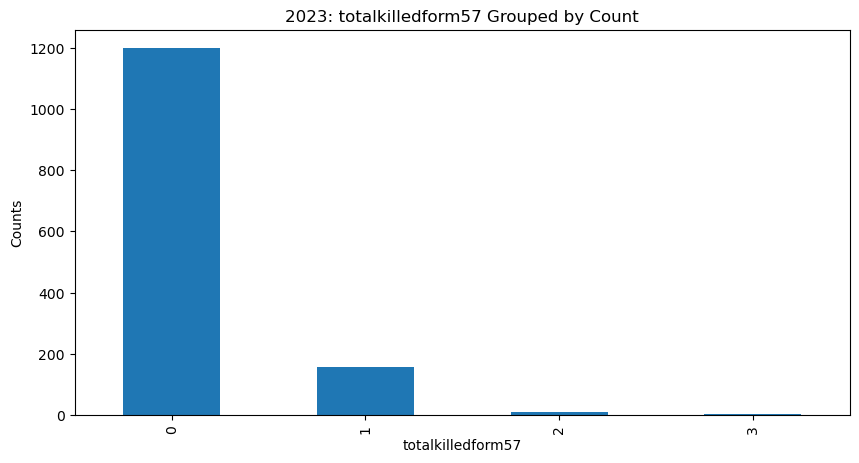

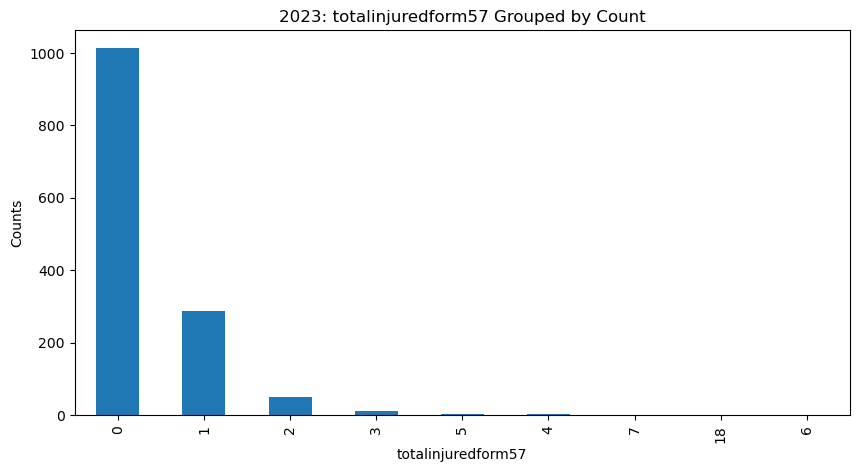

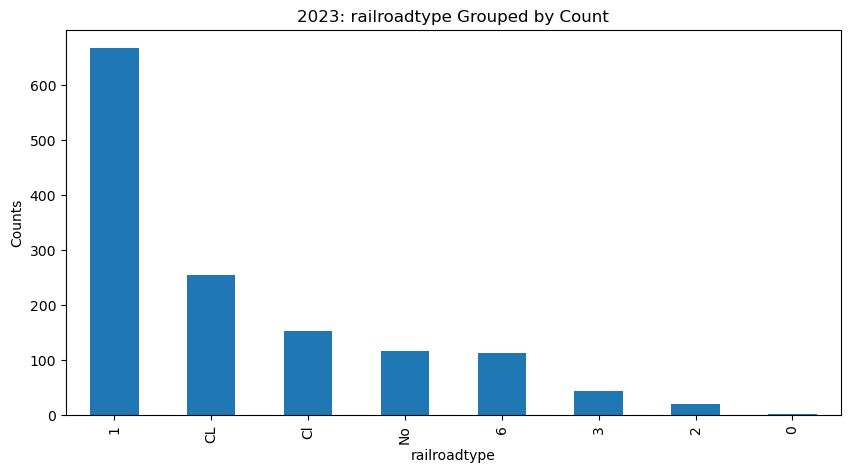

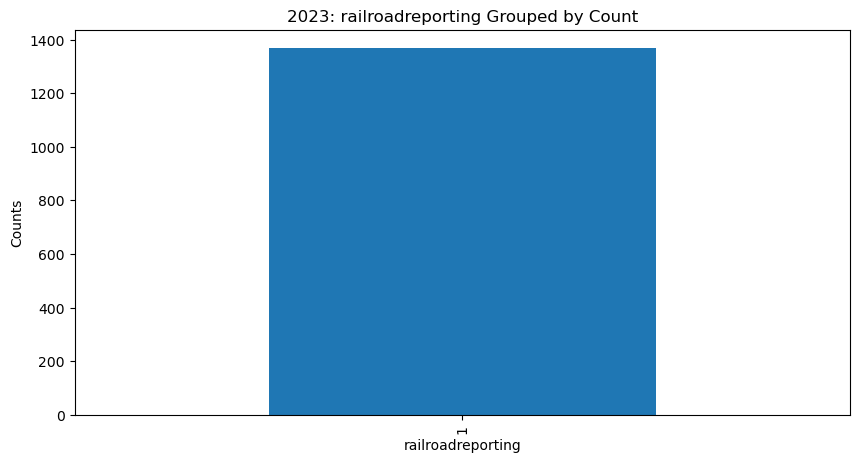

...

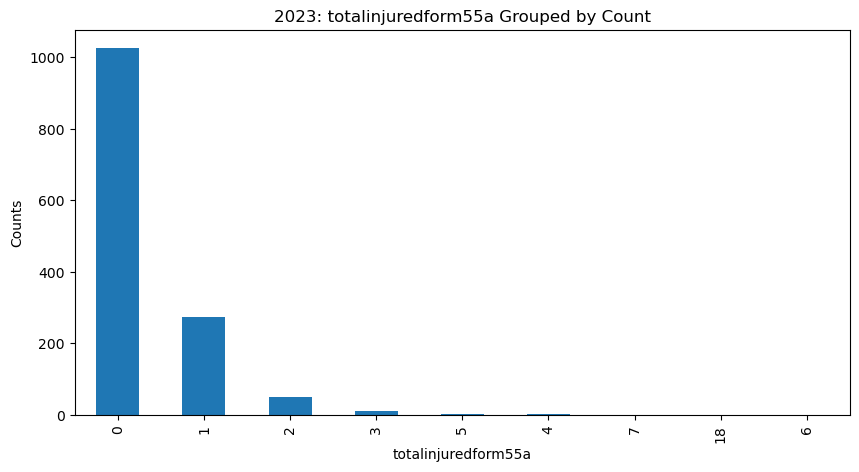

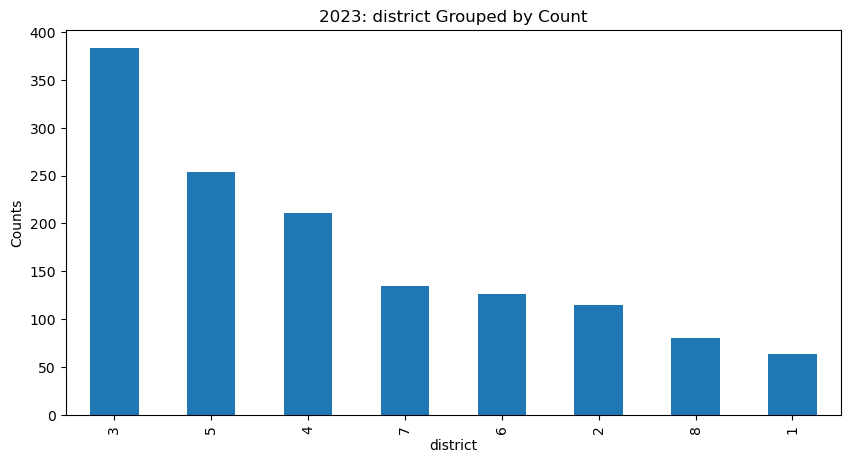

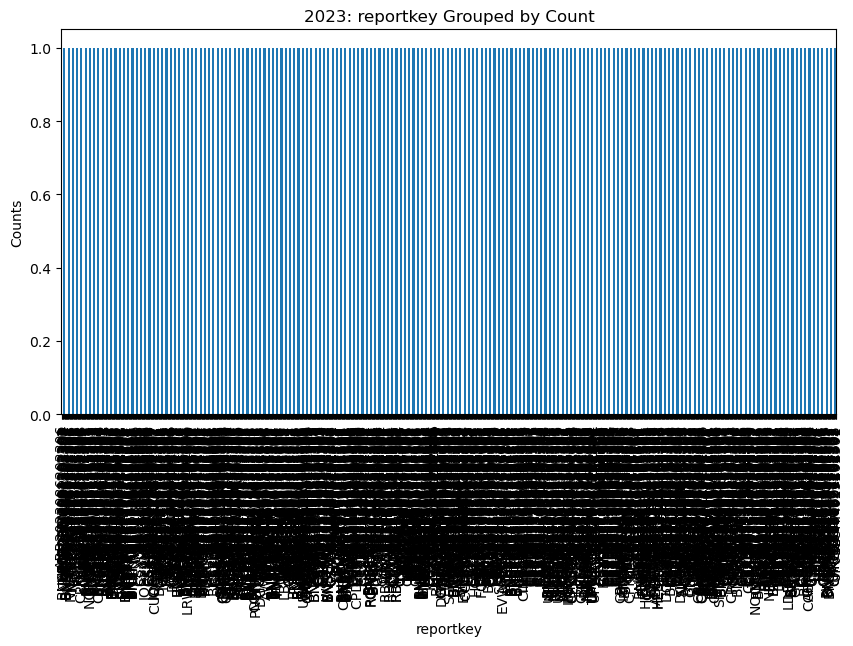

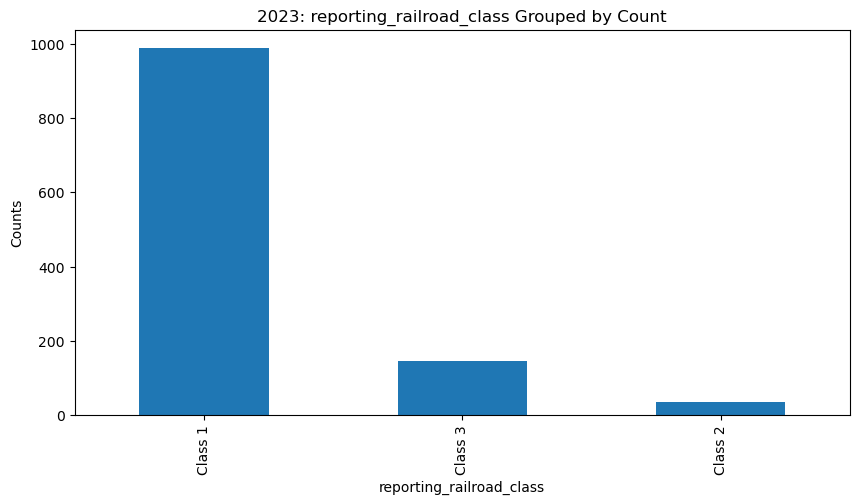

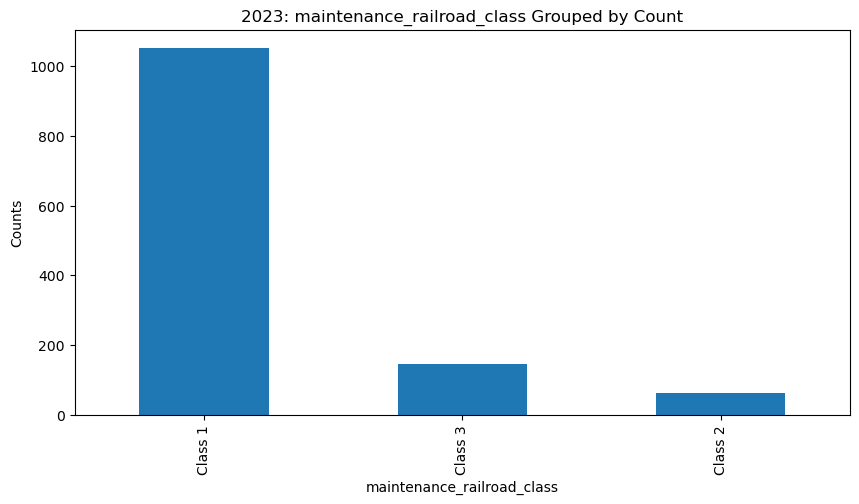

In [41]:
import matplotlib.pyplot as plt

# Iterate over each column in the DataFrame
for column in Raw_2023_clean.columns:
    # Calculate the value counts of the current column
    value_counts = Raw_2023_clean[column].value_counts()

    # Create a new figure and axis for the histogram
    plt.figure(figsize=(10, 5))

    # Plot the bar chart
    value_counts.plot.bar(title=f'2023: {column} Grouped by Count')

    # Label the axes
    plt.xlabel(column)
    plt.ylabel('Counts')

    # Show the plot
    plt.show()


### Histogram for each column in the Raw_2023_clean
create a histogram for each column in the Raw_2023_clean DataFrame, showing only the top 12 most frequent values if there are more than 12 unique values, or all if there are less than 12. 

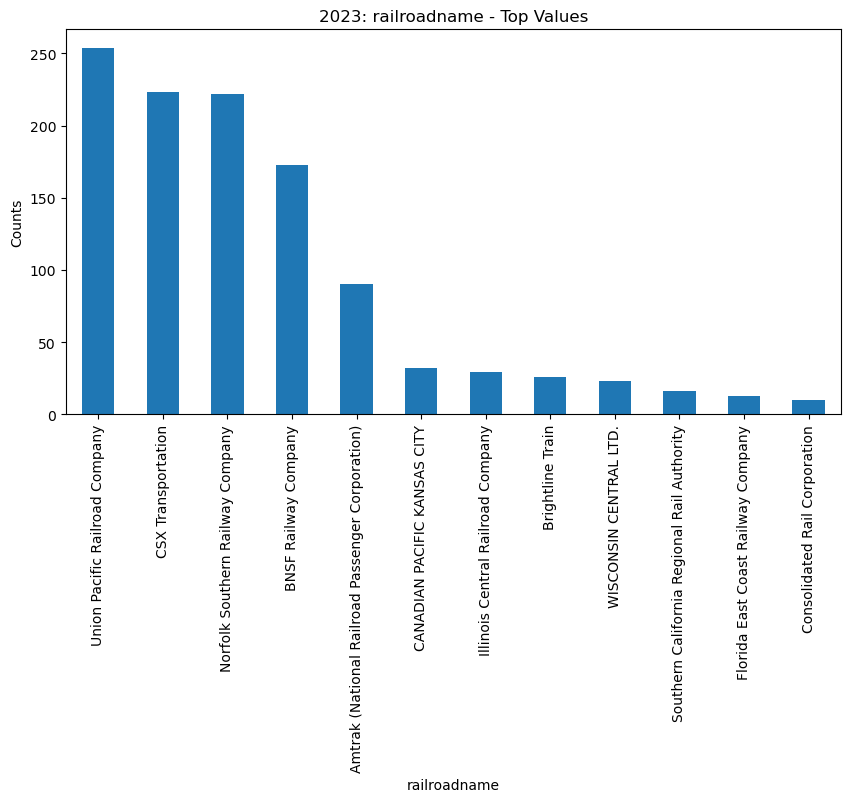

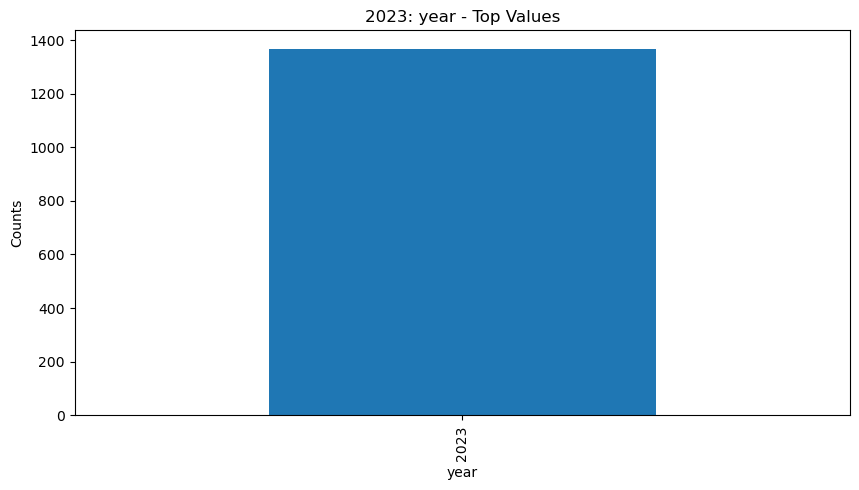

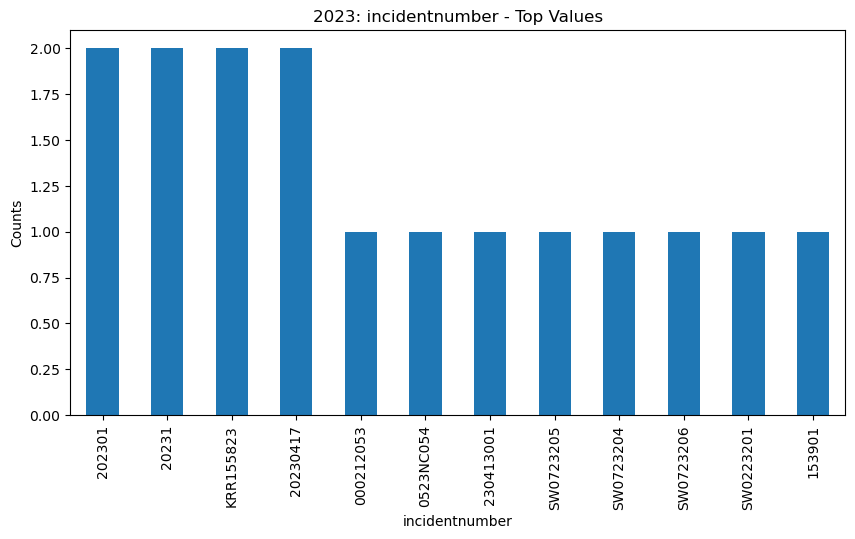

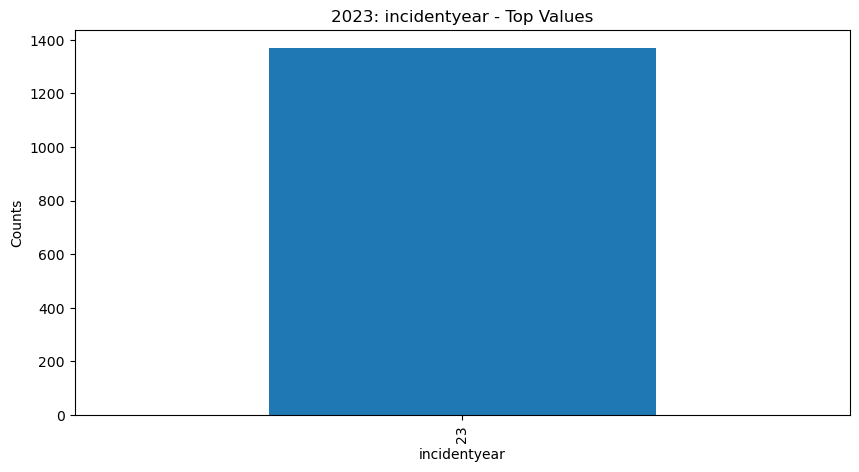

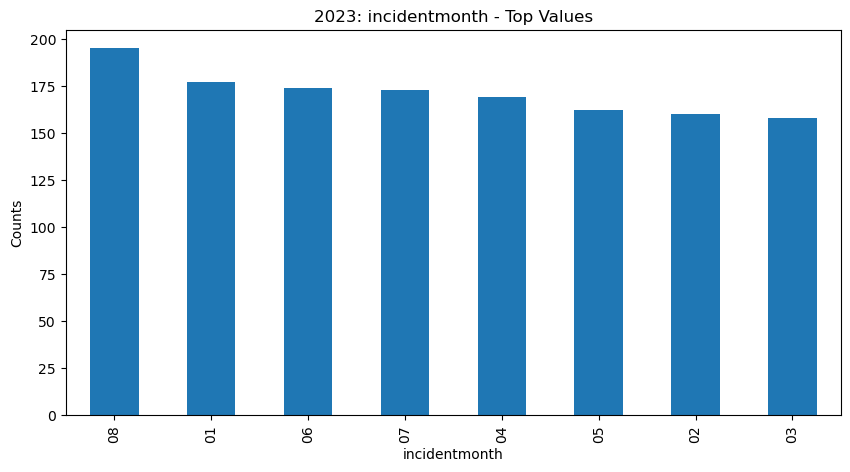

...

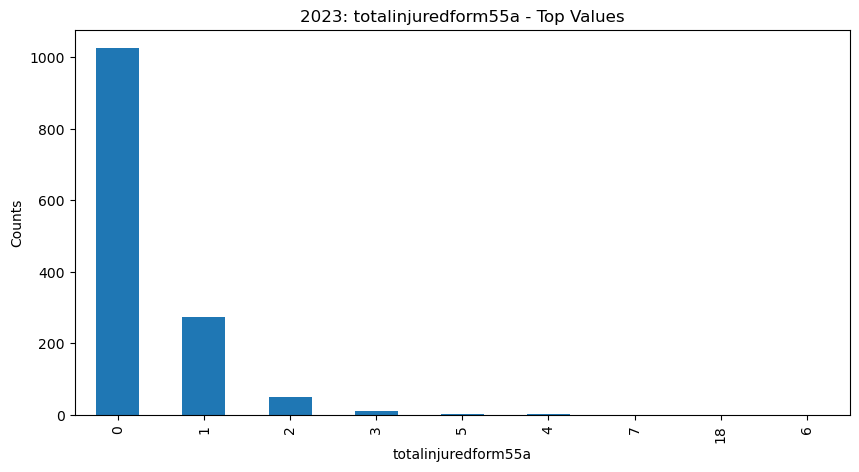

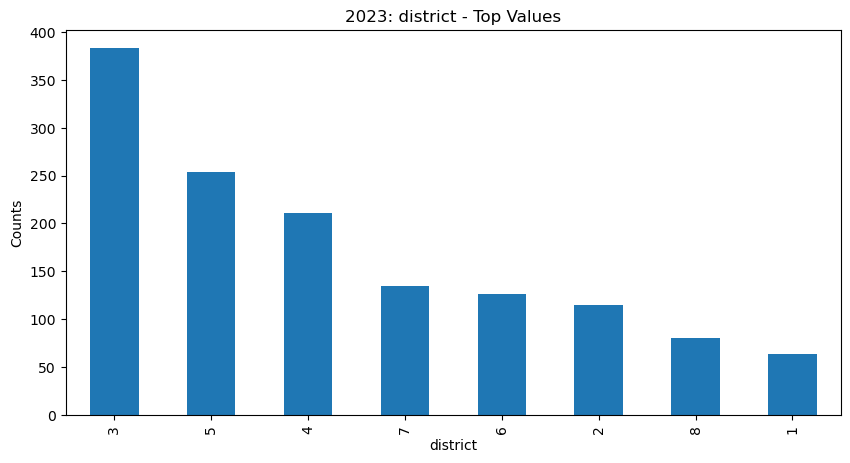

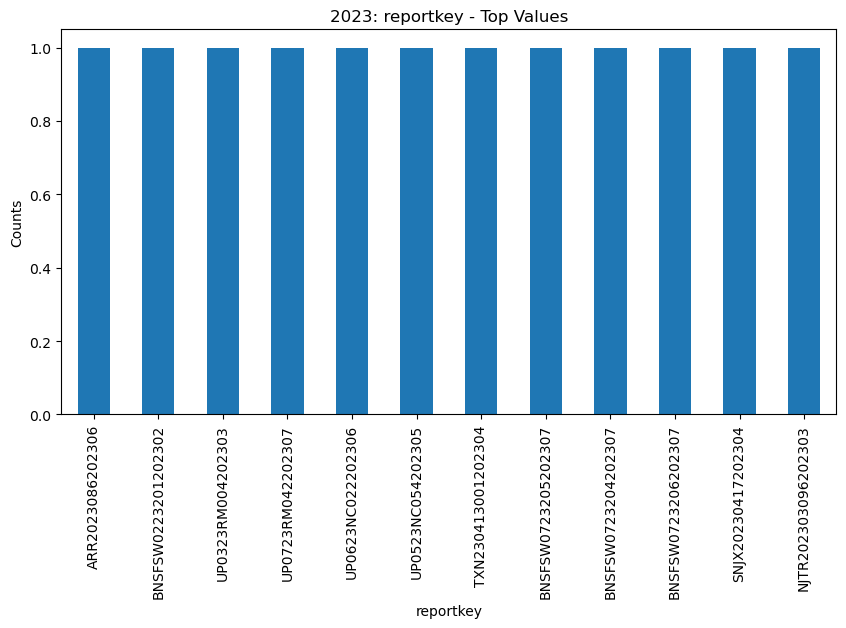

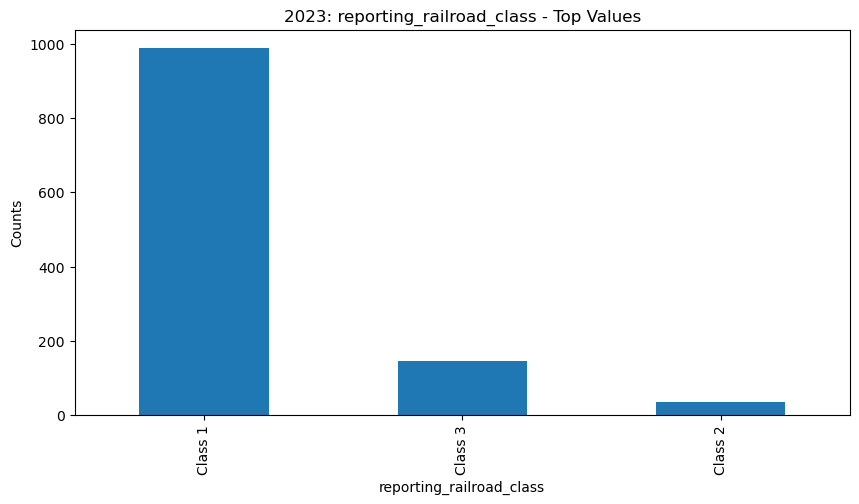

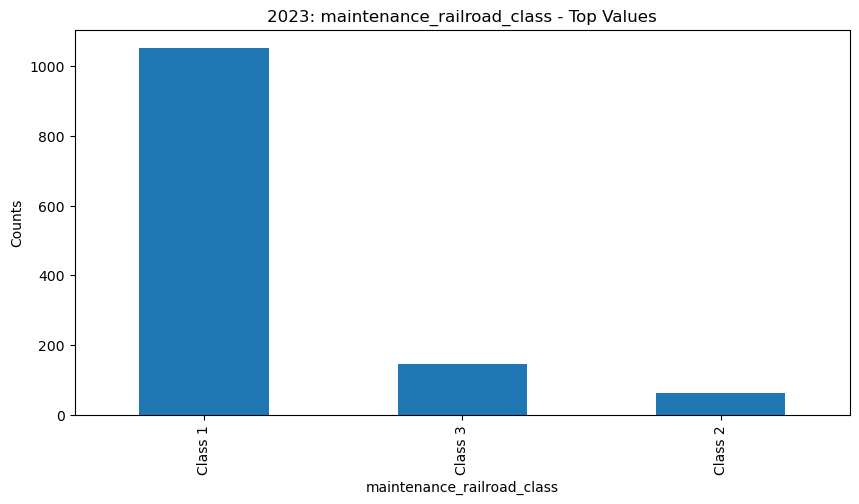

In [42]:
import matplotlib.pyplot as plt

# Iterate over each column in the DataFrame
for column in Raw_2023_clean.columns:
    # Calculate the value counts of the current column
    value_counts = Raw_2023_clean[column].value_counts()

    # Determine the number of unique values
    unique_values = len(value_counts)

    # If there are more than 12 unique values, select the top 12
    if unique_values > 12:
        value_counts = value_counts.head(12)

    # Create a new figure and axis for the histogram
    plt.figure(figsize=(10, 5))

    # Plot the bar chart
    value_counts.plot.bar(title=f'2023: {column} - Top Values')

    # Label the axes
    plt.xlabel(column)
    plt.ylabel('Counts')

    # Show the plot
    plt.show()


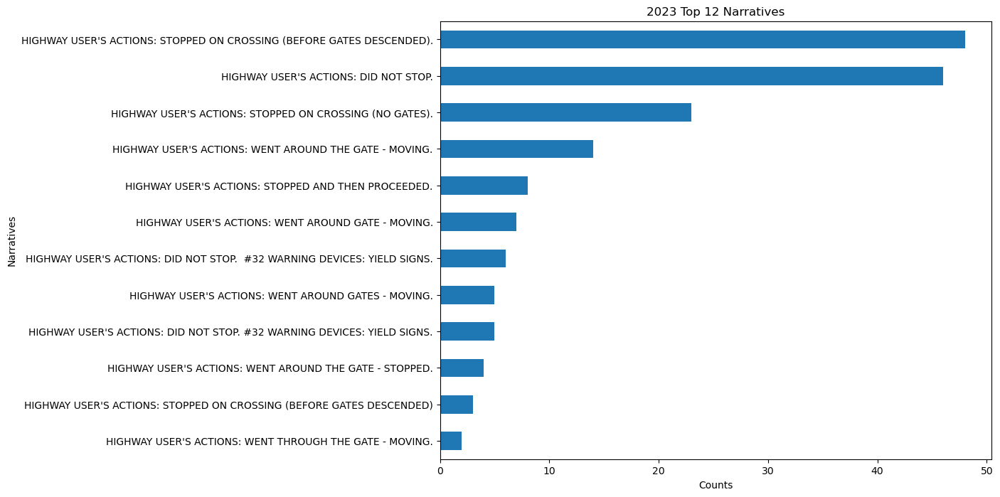

In [50]:


# Get the top occurrences in the 'narrative' column
topnarrative = Raw_2023_clean['narrative'].value_counts().head(12)

# Create a horizontal bar chart
plt.figure(figsize=(10, 8))  # You may want to adjust the figure size as needed

# Plot the bar chart with horizontal orientation
topnarrative.plot.barh(title='2023 Top 12 Narratives')

# Invert the y-axis to have the highest count at the top
plt.gca().invert_yaxis()

# Label the axes
plt.xlabel('Counts')
plt.ylabel('Narratives')

# Show the plot
plt.show()


Now that we understand our conditions for an incident, lets gather all the inventory data on the invidual crossings from form 71. 

In [53]:
np.savez('../Data/Internal/processed/2023form54ids.npz', Raw_2023_clean['gradecrossingid'].to_numpy())

TypeError: expected str, bytes or os.PathLike object, not ndarray